# Factor Theme Portfolios and Regression Analysis

Builds quintile portfolios for six JKP factor themes (quality, value, momentum, profitability, size, debt issuance), forms long-short factor series from the top and bottom quintiles, and regresses a factor-mix portfolio on the SPI and the factor series.

**Framework parts used:** `backtesting` (service, item builders including `bibfn_selection_jkp_data_scores`, `Backtest`), `optimization.optimization.PercentilePortfolio`, `estimation.covariance`, `helper_functions`.


In [1]:
# Standard library imports
import os
import sys

# Third party imports
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Make framework/, signals/ and data_utils/ importable
project_root = os.getcwd()
while not os.path.isdir(os.path.join(project_root, 'framework')):
    if os.path.dirname(project_root) == project_root:
        raise FileNotFoundError('Could not locate the repository root (folder containing framework/).')
    project_root = os.path.dirname(project_root)
for module_dir in ('framework', 'signals', 'data_utils'):
    sys.path.insert(0, os.path.join(project_root, module_dir))

# Local modules imports
from helper_functions import (
    load_pickle,
    load_data_spi,
    align_market_data_with_jkp_data,
)
from estimation.covariance import Covariance
from optimization.optimization import PercentilePortfolio
from backtesting.backtest_item_builder.bib_classes import (
    SelectionItemBuilder,
    OptimizationItemBuilder,
)
from backtesting.backtest_item_builder.bibfn_selection import (
    bibfn_selection_gaps,
    bibfn_selection_min_volume,
    bibfn_selection_jkp_data_scores,
)
from backtesting.backtest_item_builder.bibfn_optimization_data import (
    bibfn_scores,
)
from backtesting.backtest_data import BacktestData
from backtesting.backtest_service import BacktestService
from backtesting.backtest import Backtest

## Constants

In [2]:
PATH_TO_DATA = os.path.join(project_root, 'data') + os.sep
missing = [f for f in ['market_data.parquet', 'jkp_data.parquet', 'spi_index.csv'] if not os.path.exists(PATH_TO_DATA + f)]
if missing:
    raise FileNotFoundError(f'Missing in {PATH_TO_DATA}: {missing}. See data/README.md.')
SAVE_PATH = os.path.join(project_root, 'use_cases', 'outputs') + os.sep
os.makedirs(SAVE_PATH, exist_ok=True)


## Load data and initialize BacktestData class
- market data (from parquet file)
- jkp data (from parquet file)
- swiss performance index, SPI (from csv file)

In [3]:
# Load market and jkp data from parquet files
market_data = pd.read_parquet(path = f'{PATH_TO_DATA}market_data.parquet')
jkp_data = pd.read_parquet(path = f'{PATH_TO_DATA}jkp_data.parquet')
spi = load_data_spi(path=PATH_TO_DATA)

# Align market data with jkp data
market_data_ffill, jkp_data = align_market_data_with_jkp_data(market_data=market_data, jkp_data=jkp_data)

# Instantiate the BacktestData class
# and set the market, jkp, and benchmark data as attributes
data = BacktestData()
data.market_data = market_data_ffill  # notice that we use the forward filled market data here
data.jkp_data = jkp_data
data.bm_series = spi

## Define a grid of rebalancing dates

In [4]:
n_month = 3 # We want to rebalance every n_month months
jkp_data_dates = (
    jkp_data
    .index.get_level_values('date')
    .unique().sort_values()
)
rebdates = (
    jkp_data_dates[
        jkp_data_dates > market_data.index.get_level_values('date').min()
    ][::n_month]
    .strftime('%Y-%m-%d').tolist()
)
rebdates = [date for date in rebdates if date > '2002-01-01']
rebdates

['2002-01-31',
 '2002-04-30',
 '2002-07-31',
 '2002-10-31',
 '2003-01-31',
 '2003-04-30',
 '2003-07-31',
 '2003-10-31',
 '2004-01-31',
 '2004-04-30',
 '2004-07-31',
 '2004-10-31',
 '2005-01-31',
 '2005-04-30',
 '2005-07-31',
 '2005-10-31',
 '2006-01-31',
 '2006-04-30',
 '2006-07-31',
 '2006-10-31',
 '2007-01-31',
 '2007-04-30',
 '2007-07-31',
 '2007-10-31',
 '2008-01-31',
 '2008-04-30',
 '2008-07-31',
 '2008-10-31',
 '2009-01-31',
 '2009-04-30',
 '2009-07-31',
 '2009-10-31',
 '2010-01-31',
 '2010-04-30',
 '2010-07-31',
 '2010-10-31',
 '2011-01-31',
 '2011-04-30',
 '2011-07-31',
 '2011-10-31',
 '2012-01-31',
 '2012-04-30',
 '2012-07-31',
 '2012-10-31',
 '2013-01-31',
 '2013-04-30',
 '2013-07-31',
 '2013-10-31',
 '2014-01-31',
 '2014-04-30',
 '2014-07-31',
 '2014-10-31',
 '2015-01-31',
 '2015-04-30',
 '2015-07-31',
 '2015-10-31',
 '2016-01-31',
 '2016-04-30',
 '2016-07-31',
 '2016-10-31',
 '2017-01-31',
 '2017-04-30',
 '2017-07-31',
 '2017-10-31',
 '2018-01-31',
 '2018-04-30',
 '2018-07-

## Key data fields per factor theme

The fields for each theme follow table 9 of the [Global Factor Data documentation](https://jkpfactors-data.s3.amazonaws.com/documents/Documentation.pdf), section 10.


In [5]:
JKP_FIELDS_QUALITY = [
    'at_turnover',
    'cop_at',
    'cop_atl1',
    'dgp_dsale',
    'gp_at',
    'gp_atl1',
    'mispricing_perf',
    'ni_inc8q',
    'niq_at',
    'op_at',
    'op_atl1',
    'opex_at',
    'qmj_prof',
    'qmj_growth',
    'qmj_safety',
    'sale_bev',
]

JKP_FIELDS_VALUE = [
    'at_me',
    'be_me',
    'bev_mev',
    'debt_me',
    'div12m_me',
    'ebitda_mev',
    'eq_dur',
    'eqnetis_at',
    'eqnpo_12m',
    'eqnpo_me',
    'fcf_me',
    'ival_me',
    'netis_at',
    'ni_me',
    'ocf_me',
    'sale_me',
]

JKP_FIELDS_MOMENTUM = [
    'prc_highprc_252d',
    'resff3_6_1',
    'resff3_12_1',
    'ret_3_1',
    'ret_6_1',
    'ret_9_1',
    'ret_12_1',
    'seas_1_1na',
]

# Profitability
JKP_FIELDS_THEME_1 = [
    'dolvol_var_126d',
    'ebit_bev',
    'ebit_sale',
    'f_score',
    'ni_be',
    'niq_be',
    'o_score',
    'ocf_at',
    'ope_be',
    'ope_bel1',
    'turnover_var_126d',
]

# Size
JKP_FIELDS_THEME_2 = [
    'ami_126d',
    'dolvol_126d',
    'market_equity',
    'prc',
    'rd_me',
]

# Debt issuance
JKP_FIELDS_THEME_3 = [
    'capex_abn',
    'debt_gr3',
    'fnl_gr1a',
    'ncol_gr1a',
    'nfna_gr1a',
    'ni_ar1',
    'noa_at',
]


JKP_FIELDS = {
    'quality': JKP_FIELDS_QUALITY,
    'value': JKP_FIELDS_VALUE,
    'momentum': JKP_FIELDS_MOMENTUM,
    'profitability': JKP_FIELDS_THEME_1,
    'size': JKP_FIELDS_THEME_2,
    'debt_issuance': JKP_FIELDS_THEME_3,
}

## Factor series for each theme

For each theme, runs a backtest for the top-quintile and for the bottom-quintile portfolio, simulates both return streams, and defines the factor series as long the top quintile and short the bottom quintile. Plots cumulative returns of both portfolios, the long-short factor and the benchmark.


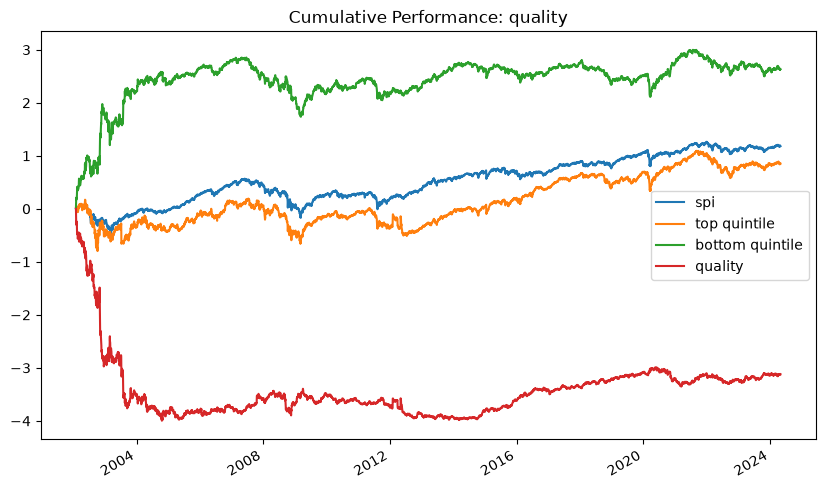

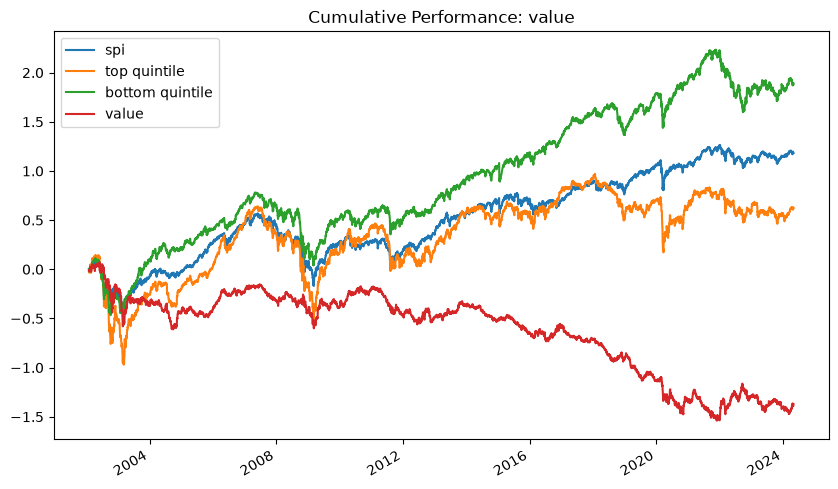

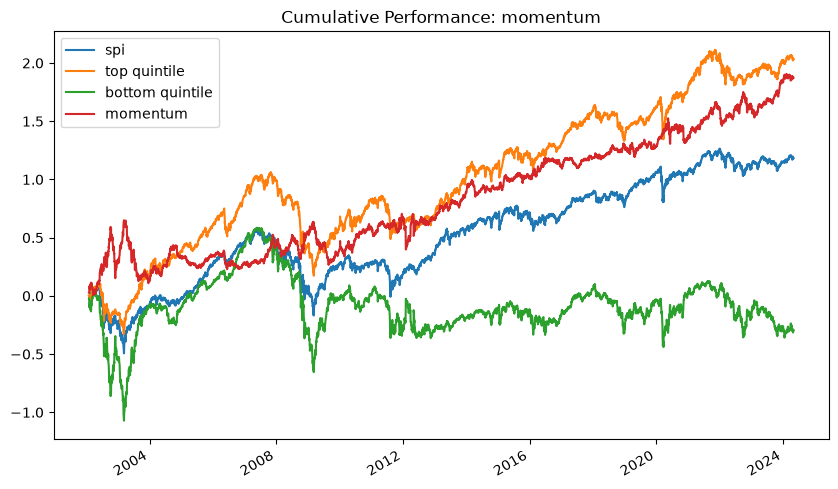

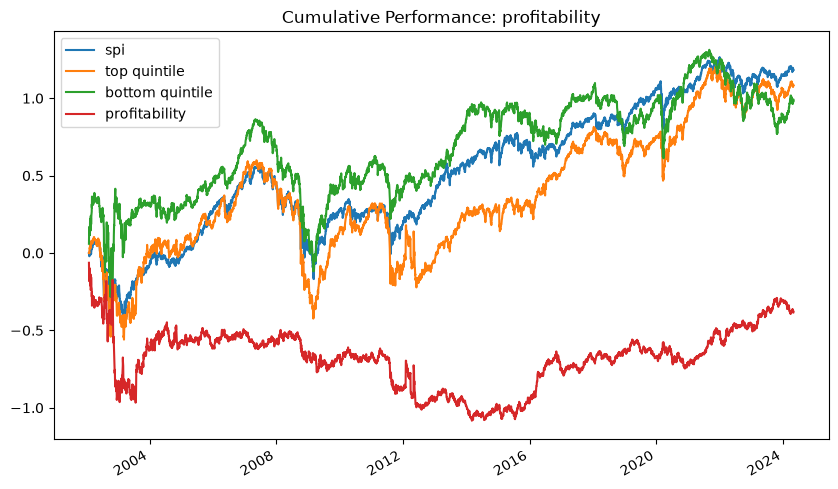

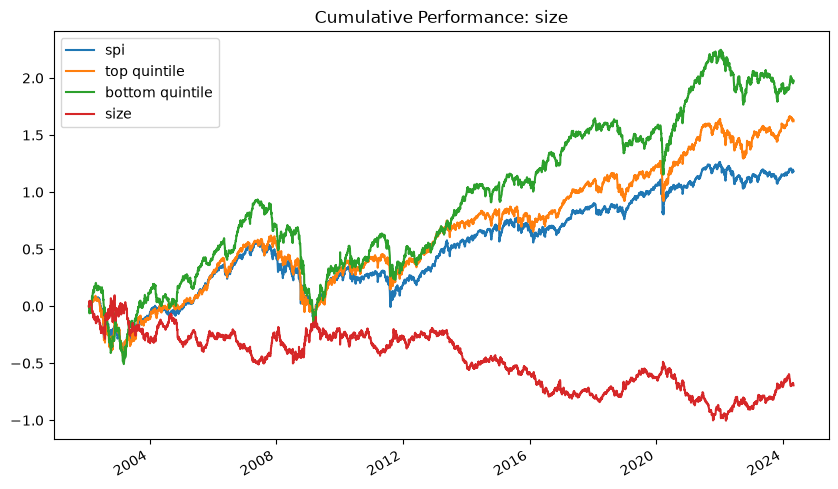

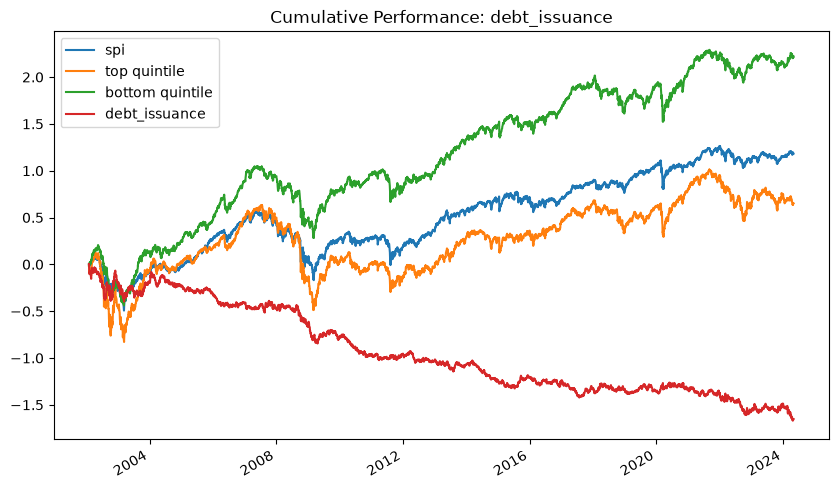

In [6]:
# Define the selection item builders
factor_themes = ['quality', 'value', 'momentum', 'profitability', 'size', 'debt_issuance']

selection_item_builders = {}
for factor_theme in factor_themes:
    selection_item_builders.update(
        {
            factor_theme:
        {
        'min_volume': SelectionItemBuilder(
            bibfn=bibfn_selection_min_volume,
            width=365,
            min_volume=500_000,
            agg_fn=np.median,
        ),
        'jkp_data_scores': SelectionItemBuilder(
            bibfn=bibfn_selection_jkp_data_scores,                   
            fields=JKP_FIELDS[factor_theme],   # See jkp_data.columns for available fields
        ),
    }}
    )

# Define the optimization item builders
optimization_item_builders = {}
for factor_theme in factor_themes:
    optimization_item_builders.update(
        {
            factor_theme: {
        'scores': OptimizationItemBuilder(
            bibfn=bibfn_scores,
            fields=JKP_FIELDS[factor_theme],
        ),
    }}
    )

# Initialize the backtest service
bs = {}
for factor_theme in factor_themes:
    bs.update(
        {
            factor_theme:
            BacktestService(
            data=data,
            selection_item_builders=selection_item_builders[factor_theme],
            optimization_item_builders=optimization_item_builders[factor_theme],
            rebdates=rebdates,
        )
        }
    )

# Run backtest for a top quintile portfolio (tqp)
for factor_theme in factor_themes:
    # Update the backtest service with a PercentilePortfolio optimization object
    bs[factor_theme].optimization = PercentilePortfolio(
        percentile=80,
        sign='>=',
    )

    # Instantiate the backtest object and run the backtest
    bt_tqp = Backtest()

    # Run the backtest
    bt_tqp.run(bs=bs[factor_theme])

    # Save the backtest as a .pickle file
    bt_tqp.save(
        path=SAVE_PATH,
        filename=f'factor_backtest_tqp_{factor_theme}.pickle'
    )

# Run backtest for a bottom quintile portfolio (bqp)
for factor_theme in factor_themes:
    # Update the backtest service with a PercentilePortfolio optimization object
    bs[factor_theme].optimization = PercentilePortfolio(
        percentile=20,
        sign='<=',
    )

    # Instantiate the backtest object and run the backtest
    bt_bqp = Backtest()

    # Run the backtest
    bt_bqp.run(bs=bs[factor_theme])

    # Save the backtest as a .pickle file
    bt_bqp.save(
        path=SAVE_PATH,
        filename=f'factor_backtest_bqp_{factor_theme}.pickle'
    )

# Simulate
for factor_theme in factor_themes:
    # Load backtests from pickle
    bt_tqp = load_pickle(
        filename=f'factor_backtest_tqp_{factor_theme}.pickle',
        path=SAVE_PATH,
    )
    bt_bqp = load_pickle(
        filename=f'factor_backtest_bqp_{factor_theme}.pickle',
        path=SAVE_PATH,
    )

    fixed_costs = 0
    variable_costs = 0
    return_series = bs[factor_theme].data.get_return_series()

    sim_tqp = bt_tqp.strategy.simulate(
        return_series=return_series,
        fc=fixed_costs,
        vc=variable_costs
    )
    sim_bqp = bt_bqp.strategy.simulate(
        return_series=return_series,
        fc=fixed_costs,
        vc=variable_costs
    )

    # Concatenate the simulations
    sim = pd.concat({
        'spi': bs[factor_theme].data.bm_series,
        'top quintile': sim_tqp,
        'bottom quintile': sim_bqp,
        factor_theme: sim_tqp - sim_bqp,
    }, axis=1).dropna()

    # Plot the cumulative performance
    np.log((1 + sim)).cumsum().plot(title=f'Cumulative Performance: {factor_theme}', figsize=(10, 6))
    plt.show()

**Note on the quality series.** Few stocks have all the quality fields early in the sample: the bottom quintile holds a single stock at the first six rebalancing dates (median over the sample: 11). 2002-2003 account for 2.22 of its 2.64 total log return, so the quality long-short series mostly reflects those concentrated positions.


## Factor analysis

Computes a factor-mix return series by averaging the top-quintile simulations, then runs an OLS regression of the mix on a constant, the SPI return series and the factor return series from the previous section.


In [7]:
# Factor-mix return series 
sim_tqp = {}
sim_bqp = {}
factors_returns = {}

for factor_theme in factor_themes:
    # Load backtests from pickle
    bt_tqp = load_pickle(
        filename=f'factor_backtest_tqp_{factor_theme}.pickle',
        path=SAVE_PATH,
    )
    bt_bqp = load_pickle(
        filename=f'factor_backtest_bqp_{factor_theme}.pickle',
        path=SAVE_PATH,
    )

    fixed_costs = 0
    variable_costs = 0
    return_series = bs[factor_theme].data.get_return_series()

    sim_tqp.update(
        {
            factor_theme:
            bt_tqp.strategy.simulate(
            return_series=return_series,
            fc=fixed_costs,
            vc=variable_costs
            ).dropna()
        }
    )
    sim_bqp.update(
        {
            factor_theme:
            bt_bqp.strategy.simulate(
            return_series=return_series,
            fc=fixed_costs,
            vc=variable_costs
            ).dropna()
        }
    )
    factors_returns.update(
        {
            factor_theme:
            (sim_tqp[factor_theme] - sim_bqp[factor_theme]).dropna()
    }
    )

factor_mix_returns = sum([sim_tqp[factor_theme] for factor_theme in factor_themes]) / 6
factor_mix_returns

date
2002-02-01    0.000201
2002-02-04   -0.012462
2002-02-05   -0.011968
2002-02-06   -0.005536
2002-02-07    0.000874
                ...   
2024-04-24   -0.001180
2024-04-25   -0.009214
2024-04-26    0.011563
2024-04-29    0.005884
2024-04-30   -0.006520
Length: 5771, dtype: float64

In [8]:
# Prepare the regression data
regression_data = pd.concat({
    'y': factor_mix_returns,
    'spi': bs['quality'].data.bm_series,
    'quality': factors_returns['quality'],
    'value': factors_returns['value'],
    'momentum': factors_returns['momentum'],
    'profitability': factors_returns['profitability'],
    'size': factors_returns['size'],
    'debt_issuance': factors_returns['debt_issuance'],
}, axis=1)

# Drop NaN values
regression_data = regression_data.dropna()

# Aggregate from daily to monthly frequency (if needed)
regression_data = regression_data.resample('ME').apply(lambda x: (1 + x).prod() - 1)

# Define dependent and independent variables
y = regression_data['y']  # Dependent variable
X = regression_data.drop('y', axis=1)  # All other columns as independent variables

# Add constant term
X = sm.add_constant(X)

# Fit the regression model
model = sm.OLS(y, X)
results = model.fit()

# Display regression results
print("Regression Results: sim_factor_mix on constant, SPI, and factor return series")
print(results.summary())

Regression Results: sim_factor_mix on constant, SPI, and factor return series
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.815
Model:                            OLS   Adj. R-squared:                  0.810
Method:                 Least Squares   F-statistic:                     162.7
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           5.55e-91
Time:                        08:30:48   Log-Likelihood:                 634.16
No. Observations:                 267   AIC:                            -1252.
Df Residuals:                     259   BIC:                            -1224.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------